# MS6 — Benchmark comparatif des algorithmes de clustering
### Volet 2/2 du travail data science — *Model comparison lab*

**PFE Master SDIA — Transport scolaire intelligent · Anass Zbir · Pr. Ali Bekri · FS Meknès**

---

Ce notebook **compare rigoureusement ~11 algorithmes de clustering** pour le regroupement
géospatial des 300 élèves de Meknès. Il complète `clustering_study.ipynb` (EDA + démarche
CRISP-DM + pipeline retenu) en se concentrant sur le **benchmark** : entraînement de tous les
modèles, **évaluation multi-critères**, et un large panel de **visualisations comparatives**.

**Algorithmes évalués**

| Famille | Algorithmes |
|---|---|
| Centroïdes / partition | K-Means, **K-Means capacitaire**, BIRCH |
| Probabiliste | **GMM** (mélange gaussien, affectation *soft*) |
| Graphe / spectral | **Spectral** (formes non convexes) |
| Hiérarchique | Ward (contrainte de connectivité géographique) |
| Densité | DBSCAN, **OPTICS** (densité variable), HDBSCAN, **Mean-Shift** (k auto) |

**Visualisations** : cartes de clusters, silhouettes, enveloppes convexes (recouvrement), diagramme
de Voronoï, *reachability plot* OPTICS, carte de confiance GMM, boxplots tailles/compacité, temps de
calcul, **matrice d'accord inter-modèles (ARI)**, **heatmap de classement des métriques**, **radar**,
et **score composite** final.

> Reproductible depuis `data/eleves_meknes.csv` (graine 42). Dépendances avancées optionnelles
> (pyproj, k-means-constrained) avec repli automatique.

## 0. Setup, données et projection métrique
On reprend la **projection planaire (mètres)** validée dans le notebook 1 — indispensable pour que
les distances et la Silhouette soient géographiquement correctes (pas de `StandardScaler(lat,lon)`).

**🔎 Approche.** Setup : bibliothèques, paramètres métier, chargement des données et **projection en mètres** (identique au notebook 1) pour des distances correctes.

In [1]:
import math, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps

warnings.filterwarnings("ignore")
np.set_printoptions(suppress=True)
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110

def _has(name):
    try: __import__(name); return True
    except Exception: return False

HAS_SNS    = _has("seaborn")
HAS_PYPROJ = _has("pyproj")
HAS_KMC    = _has("k_means_constrained")
try:
    from sklearn.cluster import HDBSCAN; HAS_HDBSCAN = True
except Exception:
    HAS_HDBSCAN = False
if HAS_SNS:
    import seaborn as sns; sns.set_theme(style="whitegrid")

# ----- Paramètres métier -----
BUS_CAPACITY  = 50
MIN_SILHOUETTE = 0.50
EPSG_METRIC   = 32630           # UTM 30N (Meknès)

DATA_PATH = Path("../data/eleves_meknes.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
def savefig(n): plt.tight_layout(); plt.savefig(FIG_DIR / n, dpi=130, bbox_inches="tight")

df = pd.read_csv(DATA_PATH)

def to_meters(lat, lon):
    lat = np.asarray(lat, float); lon = np.asarray(lon, float)
    if HAS_PYPROJ:
        from pyproj import Transformer
        tr = Transformer.from_crs("EPSG:4326", f"EPSG:{EPSG_METRIC}", always_xy=True)
        x, y = tr.transform(lon, lat); return np.column_stack([x, y]), "UTM 30N (pyproj)"
    lat0, lon0 = lat.mean(), lon.mean()
    x = np.radians(lon - lon0) * 6371000.0 * math.cos(math.radians(lat0))
    y = np.radians(lat - lat0) * 6371000.0
    return np.column_stack([x, y]), "Plan tangent local"

XY, PROJ = to_meters(df["latitude"].values, df["longitude"].values)
truth = df["quartier"].values
N = len(df); K = math.ceil(N / BUS_CAPACITY)
print(f"{N} élèves | projection: {PROJ} | capacité={BUS_CAPACITY} -> k(capacité)={K}")
print(f"seaborn={HAS_SNS} pyproj={HAS_PYPROJ} k-means-constrained={HAS_KMC} HDBSCAN={HAS_HDBSCAN}")

300 élèves | projection: UTM 30N (pyproj) | capacité=50 -> k(capacité)=6
seaborn=True pyproj=True k-means-constrained=True HDBSCAN=True


## 1. Registre des algorithmes

Chaque modèle renvoie un vecteur de labels (`-1` = bruit). Les méthodes **basées sur k** utilisent
`k = ⌈N/capacité⌉` (cohérence avec la contrainte métier) ; les méthodes de **densité** déterminent
le nombre de groupes automatiquement.

**🔎 Approche.** On construit un **catalogue** des ~11 algorithmes à comparer. Les méthodes « à k » utilisent k = ⌈N/capacité⌉ ; les méthodes de densité trouvent k toutes seules. On calibre aussi l'`eps` de DBSCAN.

In [2]:
from sklearn.cluster import (KMeans, DBSCAN, OPTICS, Birch, SpectralClustering,
                             AgglomerativeClustering, MeanShift, estimate_bandwidth)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, kneighbors_graph

def _eps_kdistance(X, min_samples=5):
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
    d, _ = nn.kneighbors(X)
    kd = np.sort(d[:, -1])
    try:
        from kneed import KneeLocator
        kl = KneeLocator(range(len(kd)), kd, curve="convex", direction="increasing")
        return float(kd[kl.knee]) if kl.knee else float(np.percentile(kd, 95))
    except Exception:
        d2 = np.diff(kd, 2)
        return float(kd[int(np.argmax(d2)) + 1]) if len(d2) else float(np.percentile(kd, 95))

EPS = _eps_kdistance(XY, 5)

def kmeans_capacitaire(X, k, size_max):
    if HAS_KMC:
        from k_means_constrained import KMeansConstrained
        return KMeansConstrained(n_clusters=k, size_max=size_max,
                                 random_state=RANDOM_STATE, n_init=10).fit_predict(X)
    base = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    d = np.linalg.norm(X[:, None] - base.cluster_centers_[None], axis=2)
    cap = {c: 0 for c in range(k)}; lab = -np.ones(len(X), int)
    for i in np.argsort(d.min(1)):
        for c in np.argsort(d[i]):
            if cap[c] < size_max: lab[i] = c; cap[c] += 1; break
    return lab

# Registre : nom -> (fonction, "k-based"|"auto")
ALGOS = {
    "K-Means":            (lambda X: KMeans(K, random_state=RANDOM_STATE, n_init=10).fit_predict(X), "k"),
    "K-Means capacitaire":(lambda X: kmeans_capacitaire(X, K, BUS_CAPACITY), "k"),
    "GMM":                (lambda X: GaussianMixture(K, covariance_type="full", random_state=RANDOM_STATE).fit_predict(X), "k"),
    "Spectral":           (lambda X: SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=12,
                                                        assign_labels="kmeans", random_state=RANDOM_STATE).fit_predict(X), "k"),
    "BIRCH":              (lambda X: Birch(n_clusters=K).fit_predict(X), "k"),
    "Ward connecté":      (lambda X: AgglomerativeClustering(K, linkage="ward",
                                       connectivity=kneighbors_graph(X, 10, include_self=False)).fit_predict(X), "k"),
    "DBSCAN":             (lambda X: DBSCAN(eps=EPS, min_samples=5).fit_predict(X), "auto"),
    "OPTICS":             (lambda X: OPTICS(min_samples=5, xi=0.05, min_cluster_size=0.04).fit_predict(X), "auto"),
    "Mean-Shift":         (lambda X: MeanShift(bandwidth=estimate_bandwidth(X, quantile=0.2, random_state=RANDOM_STATE)).fit_predict(X), "auto"),
}
if HAS_HDBSCAN:
    ALGOS["HDBSCAN"] = (lambda X: HDBSCAN(min_cluster_size=max(5, BUS_CAPACITY // 4)).fit_predict(X), "auto")

print(f"{len(ALGOS)} algorithmes | eps DBSCAN ≈ {EPS:.0f} m")
print(" • " + "\n • ".join(ALGOS))

10 algorithmes | eps DBSCAN ≈ 220 m
 • K-Means
 • K-Means capacitaire
 • GMM
 • Spectral
 • BIRCH
 • Ward connecté
 • DBSCAN
 • OPTICS
 • Mean-Shift
 • HDBSCAN


## 2. Entraînement de tous les modèles (avec mesure du temps de calcul)

**🔎 Approche.** On **entraîne chaque algorithme** sur les mêmes données et on mesure son temps de calcul — base d'une comparaison équitable.

In [3]:
results, timings = {}, {}
for name, (fn, kind) in ALGOS.items():
    t0 = time.perf_counter()
    try:
        lab = np.asarray(fn(XY))
        timings[name] = time.perf_counter() - t0
        results[name] = lab
        nclu = len(set(lab)) - (1 if -1 in lab else 0)
        print(f"{name:22} -> {nclu:2d} clusters, {(lab==-1).sum():3d} bruit  ({timings[name]*1000:.0f} ms)")
    except Exception as e:
        print(f"{name:22} -> ÉCHEC : {e}")
KIND = {n: k for n, (_, k) in ALGOS.items()}

K-Means                ->  6 clusters,   0 bruit  (5984 ms)
K-Means capacitaire    ->  6 clusters,   0 bruit  (155 ms)
GMM                    ->  6 clusters,   0 bruit  (16 ms)


Spectral               ->  6 clusters,   0 bruit  (64 ms)
BIRCH                  ->  6 clusters,   0 bruit  (26 ms)
Ward connecté          ->  6 clusters,   0 bruit  (13 ms)
DBSCAN                 -> 15 clusters,  16 bruit  (2 ms)


OPTICS                 -> 16 clusters,  52 bruit  (174 ms)


Mean-Shift             ->  3 clusters,   0 bruit  (542 ms)
HDBSCAN                -> 10 clusters,  42 bruit  (7 ms)


## 3. Tableau d'évaluation multi-critères

Indices internes (Silhouette ↑, Davies-Bouldin ↓, Calinski-Harabasz ↑), **KPI métier** (faisabilité
capacité, compacité en mètres, équilibre des tailles), **validation externe** vs quartiers réels
(ARI/AMI ↑), et temps de calcul.

**🔎 Approche.** On définit puis applique la fonction d'**évaluation multi-critères** (qualité interne + KPI métier + accord avec les quartiers + temps) pour obtenir le tableau comparatif.

In [4]:
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, adjusted_mutual_info_score)

def intra(X, lab):
    means, maxs = [], []
    for c in set(lab):
        if c == -1: continue
        pts = X[lab == c]
        if len(pts) == 0: continue
        cen = pts.mean(0); d = np.linalg.norm(pts - cen, axis=1)
        means.append(d.mean()); maxs.append(d.max())
    return (np.mean(means) if means else np.nan), (np.max(maxs) if maxs else np.nan)

def evaluate(X, lab, truth, cap, t=None):
    lab = np.asarray(lab); m = lab != -1; uniq = set(lab[m])
    sizes = [int((lab == c).sum()) for c in uniq]
    ok2 = len(uniq) >= 2
    im, ix = intra(X, lab)
    return {
        "n_clusters": len(uniq), "n_bruit": int((lab == -1).sum()),
        "silhouette": silhouette_score(X[m], lab[m]) if ok2 else np.nan,
        "davies_bouldin": davies_bouldin_score(X[m], lab[m]) if ok2 else np.nan,
        "calinski_harabasz": calinski_harabasz_score(X[m], lab[m]) if ok2 else np.nan,
        "intra_moy_m": im, "intra_max_m": ix,
        "taille_min": min(sizes) if sizes else 0, "taille_max": max(sizes) if sizes else 0,
        "cv_tailles": (np.std(sizes) / np.mean(sizes)) if sizes else np.nan,
        "faisab_cap_%": 100.0 * np.mean([s <= cap for s in sizes]) if sizes else 0.0,
        "ARI_quartier": adjusted_rand_score(truth[m], lab[m]) if ok2 else np.nan,
        "AMI_quartier": adjusted_mutual_info_score(truth[m], lab[m]) if ok2 else np.nan,
        "temps_ms": round(t * 1000, 1) if t else np.nan,
    }

metrics = pd.DataFrame({n: evaluate(XY, results[n], truth, BUS_CAPACITY, timings.get(n)) for n in results}).T
fmt = ["silhouette","davies_bouldin","calinski_harabasz","intra_moy_m","intra_max_m",
       "cv_tailles","faisab_cap_%","ARI_quartier","AMI_quartier"]
disp = metrics.copy()
for c in fmt: disp[c] = disp[c].astype(float).round(3)
disp.sort_values("silhouette", ascending=False)

,n_clusters,n_bruit,silhouette,davies_bouldin,calinski_harabasz,intra_moy_m,intra_max_m,taille_min,taille_max,cv_tailles,faisab_cap_%,ARI_quartier,AMI_quartier,temps_ms
OPTICS,16.0,52.0,0.673,0.436,2125.846,130.039,605.040,12.0,36.0,0.359,100.000,0.721,0.896,174.1
DBSCAN,15.0,16.0,0.605,0.502,1058.735,165.772,524.117,7.0,54.0,0.639,93.333,0.735,0.879,1.7
HDBSCAN,10.0,42.0,0.532,0.555,514.286,220.729,1228.285,12.0,65.0,0.608,90.000,0.641,0.856,7.0
Mean-Shift,3.0,0.0,0.519,0.749,457.912,760.573,2250.802,72.0,144.0,0.315,0.000,0.230,0.520,542.0
K-Means,6.0,0.0,0.513,0.738,597.710,481.786,1645.871,31.0,70.0,0.299,50.000,0.505,0.727,5983.8
BIRCH,6.0,0.0,0.510,0.736,586.494,479.495,1645.871,29.0,72.0,0.321,50.000,0.501,0.732,25.9
GMM,6.0,0.0,0.494,0.775,554.397,495.263,1664.563,31.0,67.0,0.239,50.000,0.491,0.707,16.4
Ward connecté,6.0,0.0,0.489,0.748,552.157,470.730,1645.871,31.0,68.0,0.291,50.000,0.509,0.734,13.2
K-Means capacitaire,6.0,0.0,0.375,0.908,427.328,550.892,2115.459,50.0,50.0,0.000,100.000,0.438,0.640,154.6
Spectral,6.0,0.0,0.236,1.134,108.040,596.341,2675.098,15.0,98.0,0.545,50.000,0.429,0.705,63.8


## 4. Visualisations comparatives

### 4.1 Cartes des clusters (vue d'ensemble)

**🔎 Approche.** On dessine les clusters de chaque algorithme **côte à côte** : la vue d'ensemble pour repérer les comportements très différents.

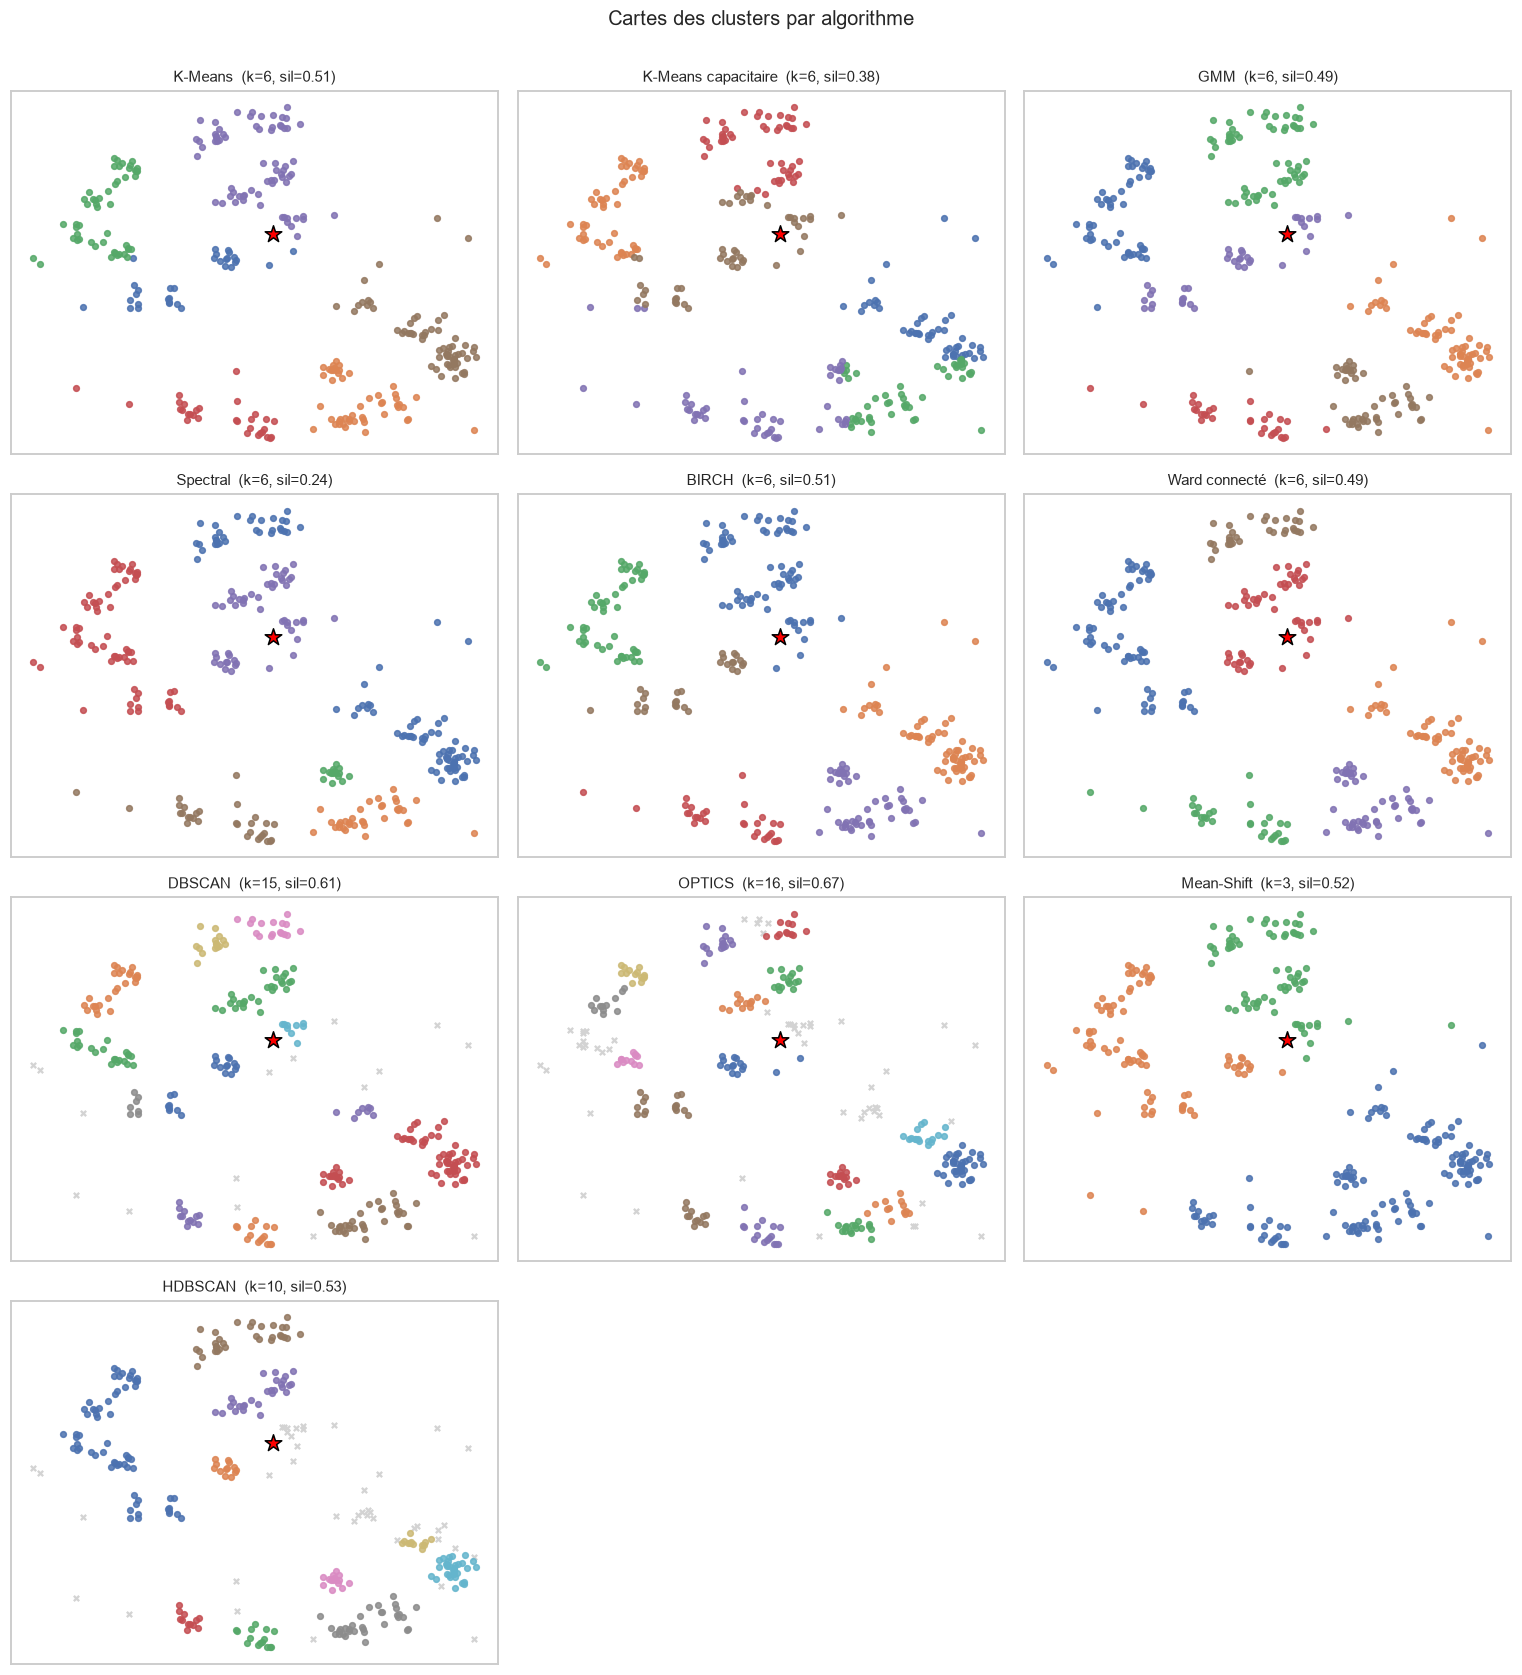

In [5]:
def plot_clusters(ax, lab, title):
    lab = np.asarray(lab)
    for c in sorted(set(lab)):
        pts = df[lab == c]
        if c == -1:
            ax.scatter(pts["longitude"], pts["latitude"], s=12, c="lightgray", marker="x")
        else:
            ax.scatter(pts["longitude"], pts["latitude"], s=14, alpha=0.85)
    ax.scatter([df["ecole_lng"].iloc[0]], [df["ecole_lat"].iloc[0]], marker="*", s=130,
               c="red", edgecolor="black", zorder=5)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])

names = list(results)
ncol = 3; nrow = math.ceil(len(names) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.8 * nrow)); axes = np.atleast_1d(axes).ravel()
for ax, n in zip(axes, names):
    plot_clusters(ax, results[n], f"{n}  (k={int(metrics.loc[n,'n_clusters'])}, sil={metrics.loc[n,'silhouette']:.2f})")
for ax in axes[len(names):]: ax.axis("off")
plt.suptitle("Cartes des clusters par algorithme", y=1.001, fontsize=13)
savefig("c01_cartes_tous_algos.png"); plt.show()

### 4.2 Profils de silhouette (qualité interne par groupe)

**🔎 Approche.** **Profils de silhouette** par algorithme : la forme et la largeur des « lames » indiquent la netteté des groupes.

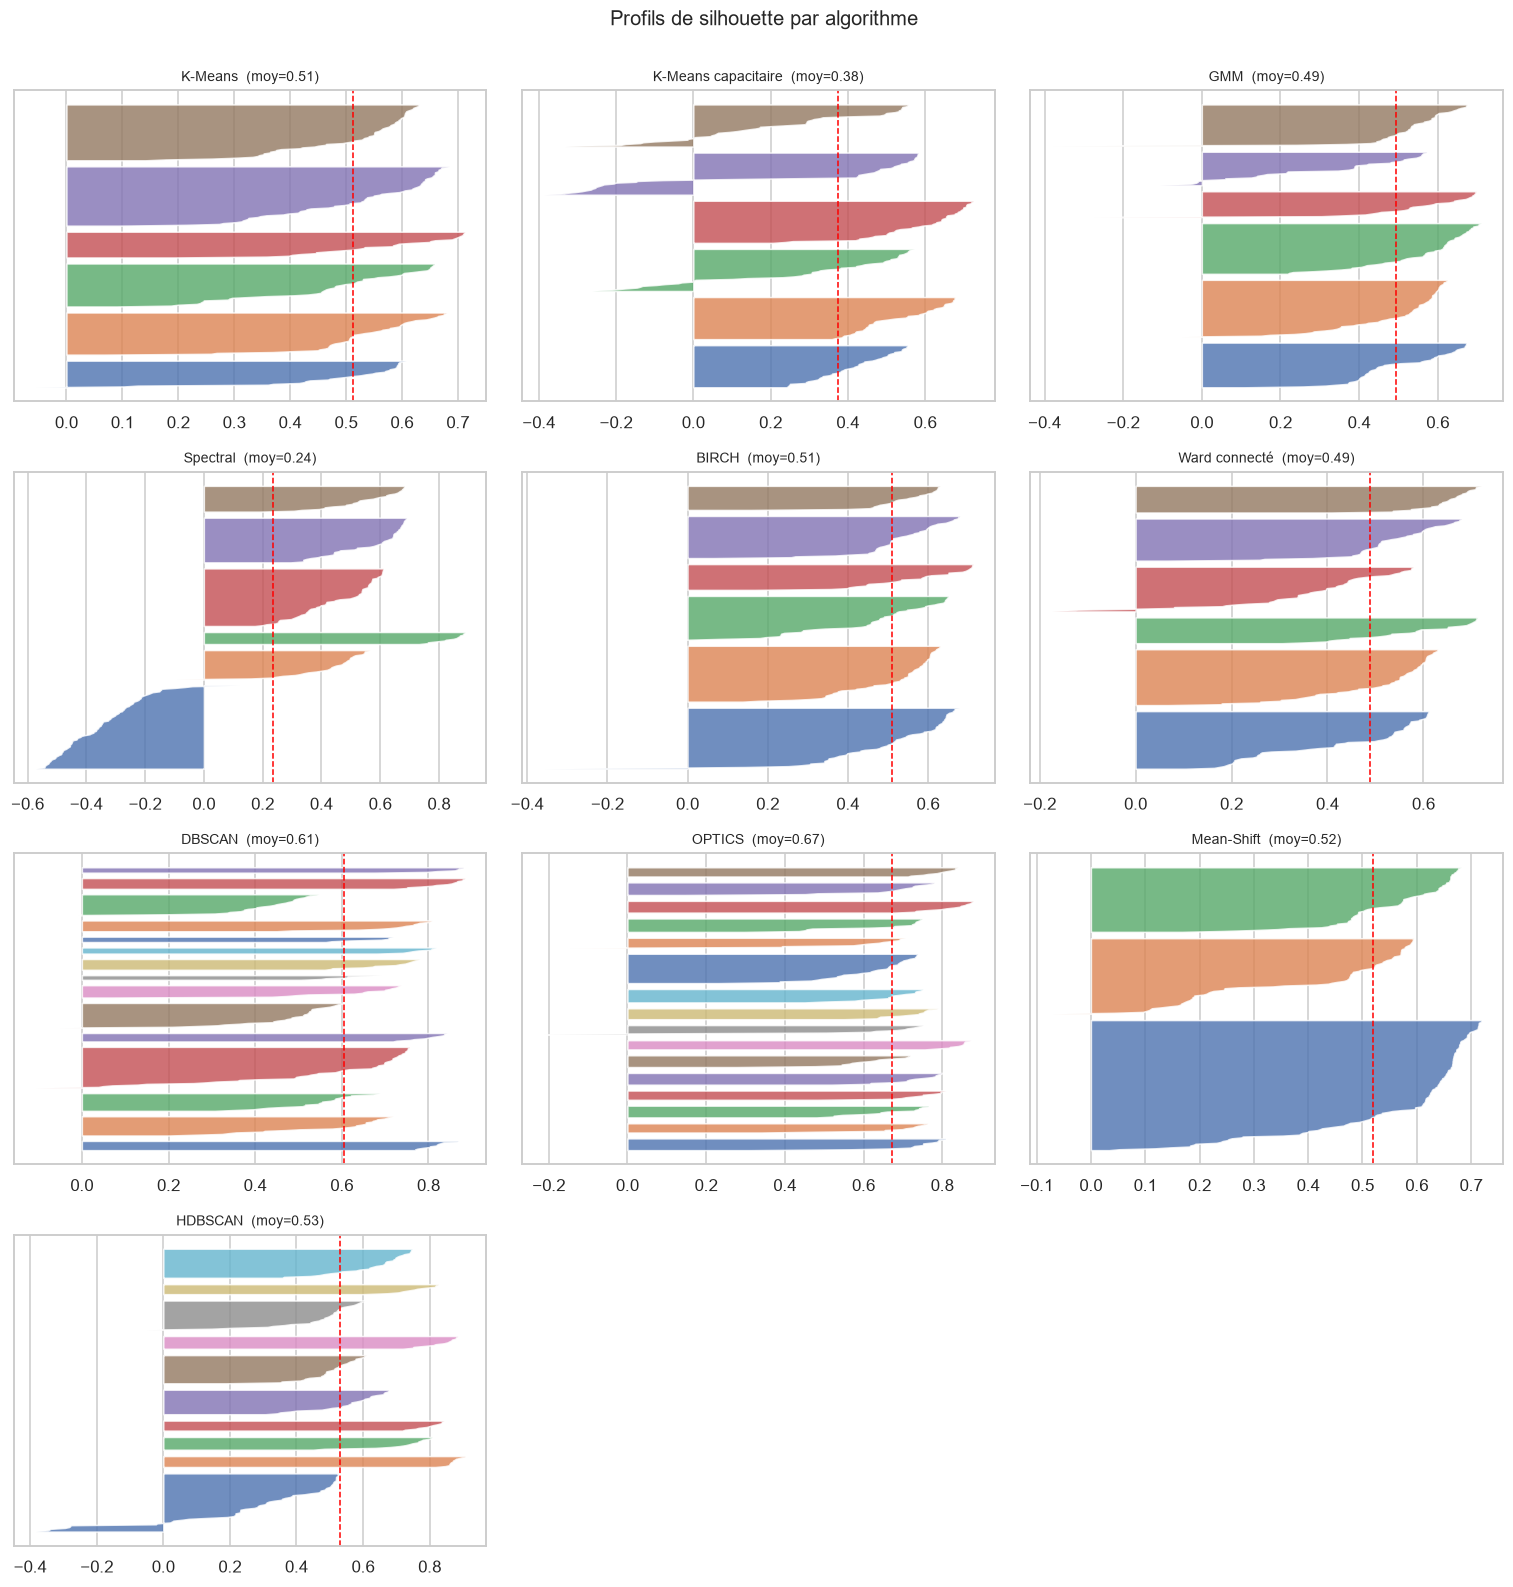

In [6]:
from sklearn.metrics import silhouette_samples
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.6 * nrow)); axes = np.atleast_1d(axes).ravel()
for ax, n in zip(axes, names):
    lab = np.asarray(results[n]); m = lab != -1
    if len(set(lab[m])) < 2:
        ax.set_title(f"{n} (n/a)", fontsize=9); ax.axis("off"); continue
    sv = silhouette_samples(XY[m], lab[m]); y0 = 0
    for c in sorted(set(lab[m])):
        v = np.sort(sv[lab[m] == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=.8); y0 += len(v) + 6
    ax.axvline(sv.mean(), color="red", ls="--", lw=1)
    ax.set_title(f"{n}  (moy={sv.mean():.2f})", fontsize=9); ax.set_yticks([])
for ax in axes[len(names):]: ax.axis("off")
plt.suptitle("Profils de silhouette par algorithme", y=1.001, fontsize=13)
savefig("c02_silhouettes.png"); plt.show()

### 4.3 Enveloppes convexes — empreinte spatiale et recouvrement des groupes
Le recouvrement des enveloppes traduit des groupes qui se chevauchent géographiquement (détours de
ramassage). Les méthodes compactes/contiguës produisent des empreintes nettes et peu superposées.

**🔎 Approche.** **Enveloppes convexes** : on trace le contour de chaque groupe ; des contours qui se chevauchent signalent des groupes mélangés géographiquement (détours de ramassage).

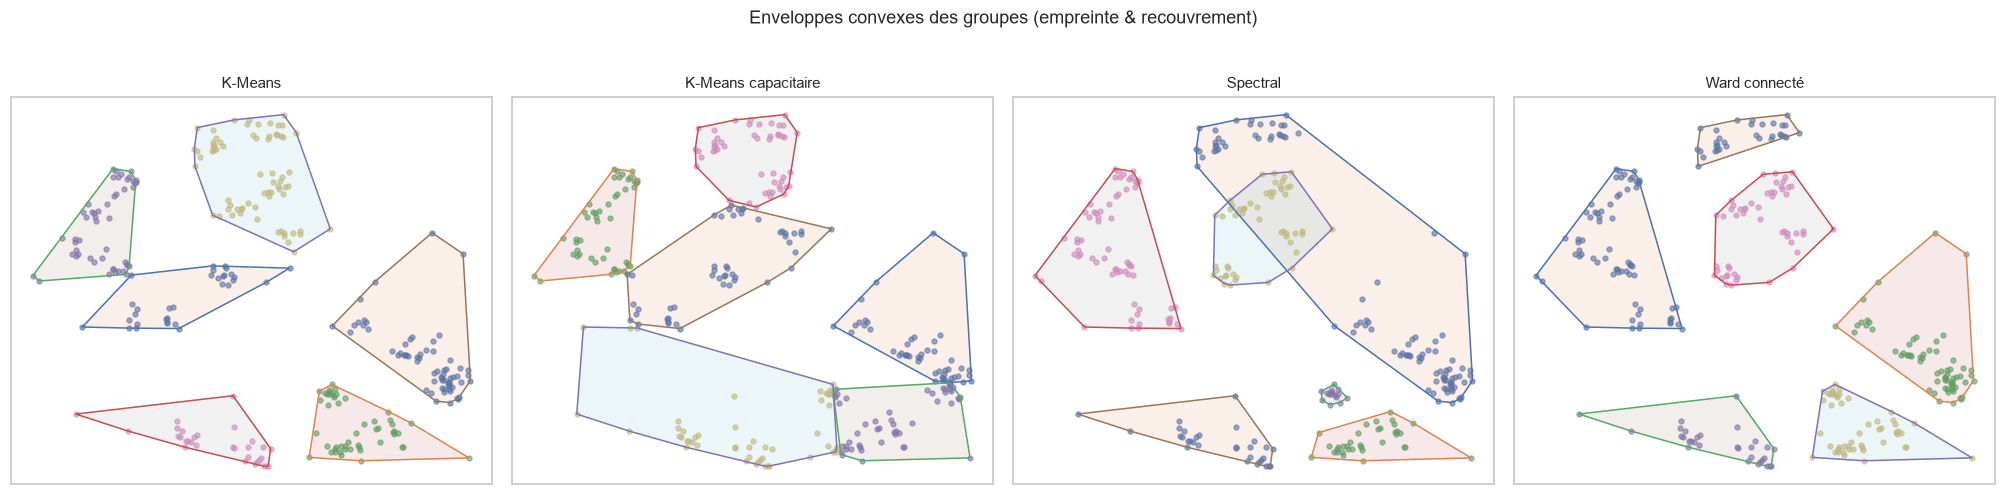

In [7]:
from scipy.spatial import ConvexHull
sel = [n for n in ["K-Means","K-Means capacitaire","Spectral","Ward connecté"] if n in results]
fig, axes = plt.subplots(1, len(sel), figsize=(4.6 * len(sel), 4.4)); axes = np.atleast_1d(axes).ravel()
for ax, n in zip(axes, sel):
    lab = np.asarray(results[n])
    for c in sorted(set(lab)):
        if c == -1: continue
        P = df.loc[lab == c, ["longitude","latitude"]].values
        ax.scatter(P[:,0], P[:,1], s=10, alpha=.6)
        if len(P) >= 3:
            try:
                h = ConvexHull(P); poly = P[h.vertices]
                ax.fill(poly[:,0], poly[:,1], alpha=.12)
                ax.plot(np.append(poly[:,0], poly[0,0]), np.append(poly[:,1], poly[0,1]), lw=1)
            except Exception: pass
    ax.set_title(n, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Enveloppes convexes des groupes (empreinte & recouvrement)", y=1.02, fontsize=12)
savefig("c03_convex_hulls.png"); plt.show()

### 4.4 Diagramme de Voronoï des centroïdes (zones d'influence — K-Means capacitaire)

**🔎 Approche.** **Diagramme de Voronoï** des centres : montre la « zone d'influence » de chaque groupe, c.-à-d. comment le territoire est découpé.

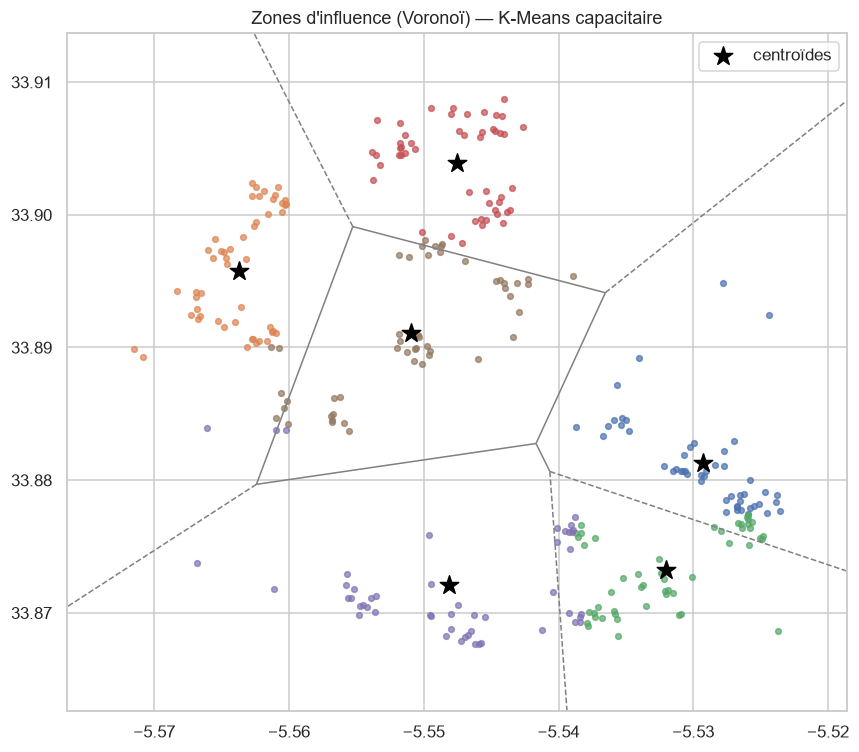

In [8]:
from scipy.spatial import Voronoi, voronoi_plot_2d
lab = np.asarray(results["K-Means capacitaire"])
cents = np.array([df.loc[lab == c, ["longitude","latitude"]].mean().values for c in sorted(set(lab)) if c != -1])
vor = Voronoi(cents)
fig, ax = plt.subplots(figsize=(8, 7))
voronoi_plot_2d(vor, ax=ax, show_vertices=False, line_colors="gray", line_width=1, point_size=0)
for c in sorted(set(lab)):
    if c == -1: continue
    P = df.loc[lab == c, ["longitude","latitude"]].values
    ax.scatter(P[:,0], P[:,1], s=14, alpha=.7)
ax.scatter(cents[:,0], cents[:,1], c="black", marker="*", s=160, label="centroïdes")
ax.set_xlim(df["longitude"].min()-.005, df["longitude"].max()+.005)
ax.set_ylim(df["latitude"].min()-.005, df["latitude"].max()+.005)
ax.set_title("Zones d'influence (Voronoï) — K-Means capacitaire"); ax.legend()
savefig("c04_voronoi.png"); plt.show()

### 4.5 Reachability plot (OPTICS) — structure de densité hiérarchique
Les « vallées » correspondent aux clusters denses ; les « pics » aux séparations / au bruit.

**🔎 Approche.** **Reachability plot** d'OPTICS : les « vallées » sont des groupes denses, les « pics » des frontières ou du bruit.

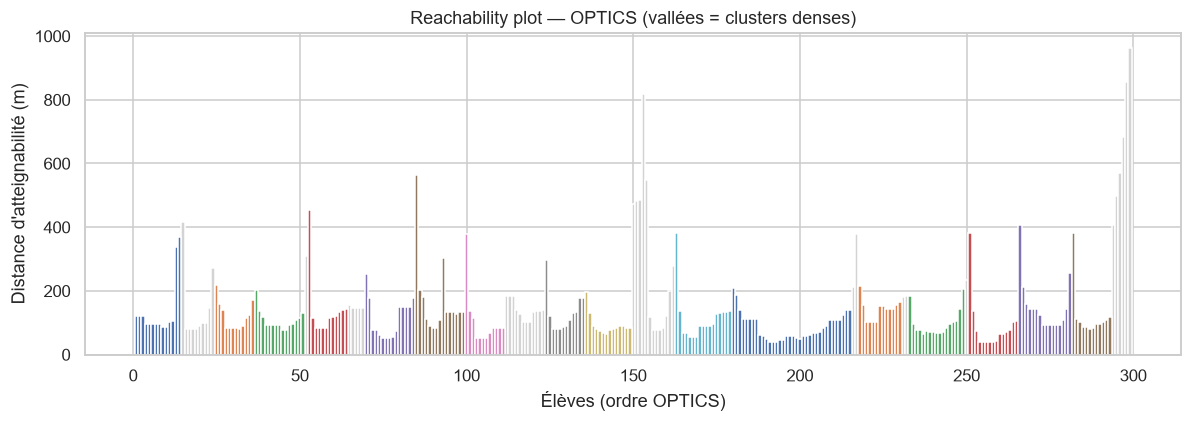

In [9]:
if "OPTICS" in results:
    from sklearn.cluster import OPTICS as _O
    op = _O(min_samples=5, xi=0.05, min_cluster_size=0.04).fit(XY)
    reach = op.reachability_[op.ordering_]; lab_o = op.labels_[op.ordering_]
    plt.figure(figsize=(11, 4))
    for c in sorted(set(lab_o)):
        idx = np.where(lab_o == c)[0]
        col = "lightgray" if c == -1 else None
        plt.bar(idx, reach[idx], width=1.0, color=col)
    plt.ylabel("Distance d'atteignabilité (m)"); plt.xlabel("Élèves (ordre OPTICS)")
    plt.title("Reachability plot — OPTICS (vallées = clusters denses)")
    savefig("c05_optics_reachability.png"); plt.show()
else:
    print("OPTICS indisponible.")

### 4.6 Affectation *soft* du GMM — carte de confiance
Le GMM fournit une probabilité d'appartenance : les points en **bordure de groupes** (faible
confiance) sont précisément ceux qu'un recalcul évolutif (S8) doit surveiller.

**🔎 Approche.** Le **GMM** donne une probabilité d'appartenance : on cartographie la **confiance**. Les points rouges (incertains) sont en bordure de groupes — à surveiller pour les recalculs évolutifs (S8).

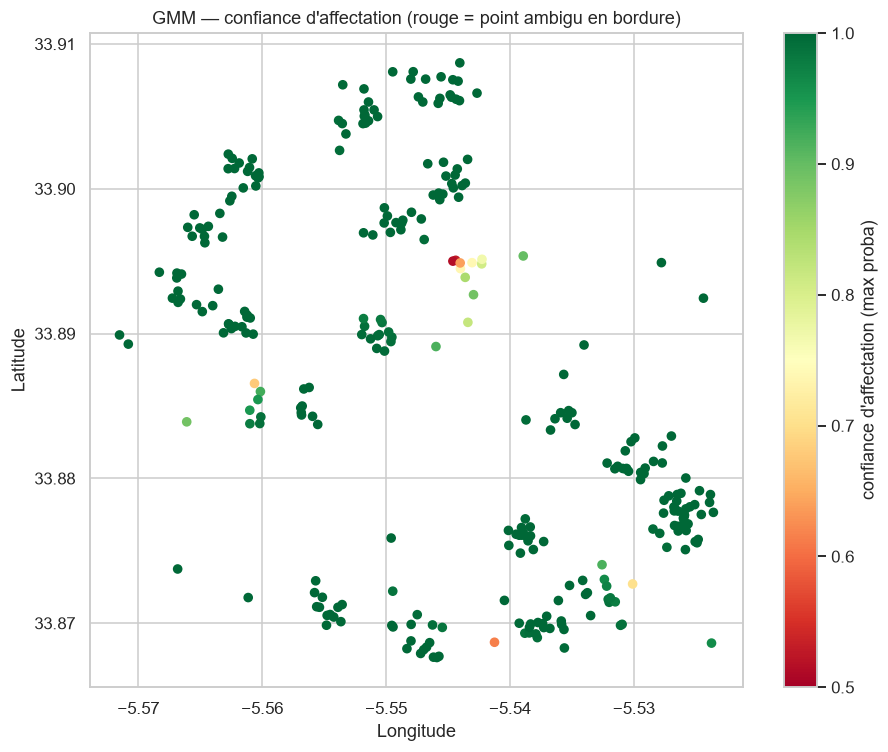

Points ambigus (confiance < 0.6) : 2 / 300


In [10]:
from sklearn.mixture import GaussianMixture
g = GaussianMixture(K, covariance_type="full", random_state=RANDOM_STATE).fit(XY)
conf = g.predict_proba(XY).max(1)
plt.figure(figsize=(8.5, 7))
sc = plt.scatter(df["longitude"], df["latitude"], c=conf, cmap="RdYlGn", s=28, vmin=.5, vmax=1)
plt.colorbar(sc, label="confiance d'affectation (max proba)")
plt.title("GMM — confiance d'affectation (rouge = point ambigu en bordure)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
savefig("c06_gmm_confiance.png"); plt.show()
print(f"Points ambigus (confiance < 0.6) : {(conf < 0.6).sum()} / {N}")

### 4.7 Tailles de groupes et compacité — lecture opérationnelle

**🔎 Approche.** **Boxplots** comparant, par algorithme, la distribution des tailles de groupes (vs capacité) et la compacité (distance au centre).

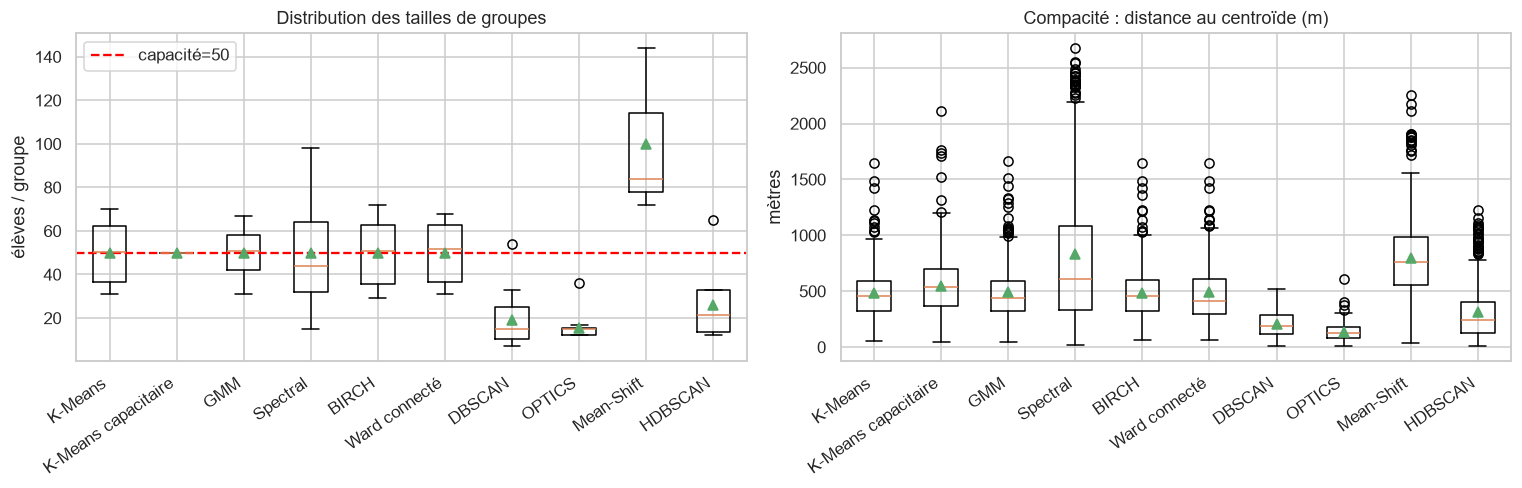

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
size_data = [[ (np.asarray(results[n]) == c).sum() for c in set(results[n]) if c != -1 ] for n in names]
ax[0].boxplot(size_data, tick_labels=names, showmeans=True)
ax[0].axhline(BUS_CAPACITY, color="red", ls="--", label=f"capacité={BUS_CAPACITY}")
ax[0].set_title("Distribution des tailles de groupes"); ax[0].set_ylabel("élèves / groupe")
ax[0].legend(); ax[0].set_xticklabels(names, rotation=35, ha="right")

intra_data = []
for n in names:
    lab = np.asarray(results[n]); ds = []
    for c in set(lab):
        if c == -1: continue
        P = XY[lab == c]; ds += list(np.linalg.norm(P - P.mean(0), axis=1))
    intra_data.append(ds)
ax[1].boxplot(intra_data, tick_labels=names, showmeans=True)
ax[1].set_title("Compacité : distance au centroïde (m)"); ax[1].set_ylabel("mètres")
ax[1].set_xticklabels(names, rotation=35, ha="right")
savefig("c07_tailles_compacite.png"); plt.show()

### 4.8 Temps de calcul

**🔎 Approche.** Comparaison des **temps de calcul** — critère pratique pour un service temps réel.

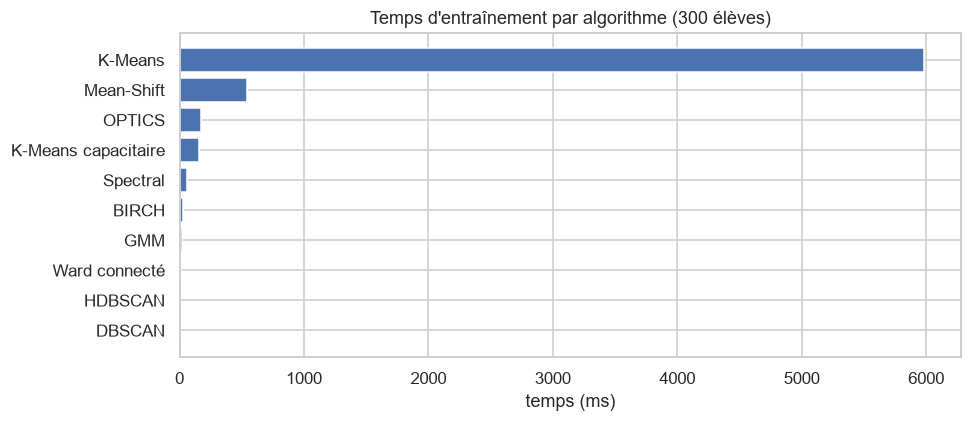

In [12]:
t = metrics["temps_ms"].astype(float).sort_values()
plt.figure(figsize=(9, 4))
plt.barh(t.index, t.values, color="#4C72B0")
plt.xlabel("temps (ms)"); plt.title("Temps d'entraînement par algorithme (300 élèves)")
savefig("c08_temps.png"); plt.show()

## 5. Accord inter-modèles (consensus)
Matrice d'**ARI** entre chaque paire d'algorithmes : un ARI élevé signifie que deux méthodes
produisent des partitions similaires. Cela révèle des **familles de solutions** et la robustesse du
regroupement (les zones où tous les modèles s'accordent sont des groupes « naturels »).

**🔎 Approche.** **Matrice d'accord (ARI)** : pour chaque paire d'algorithmes, à quel point ils produisent les mêmes groupes. Révèle des familles de méthodes et les regroupements « naturels ».

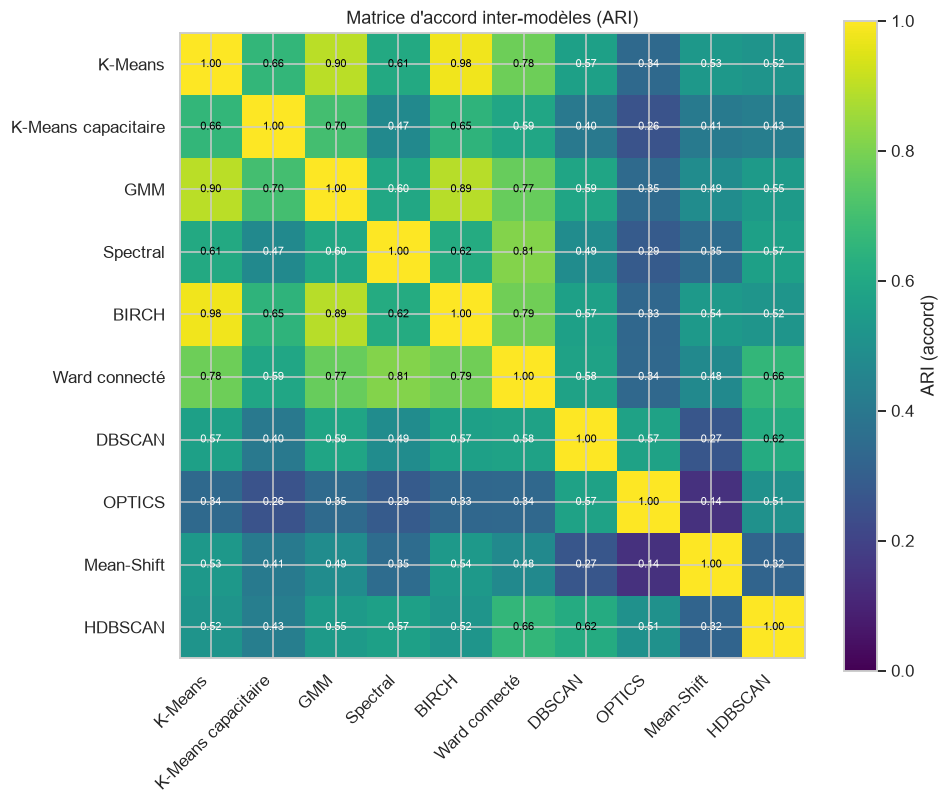

In [13]:
from sklearn.metrics import adjusted_rand_score
A = np.zeros((len(names), len(names)))
for i, a in enumerate(names):
    for j, b in enumerate(names):
        A[i, j] = adjusted_rand_score(results[a], results[b])
plt.figure(figsize=(9, 7.5))
im = plt.imshow(A, cmap="viridis", vmin=0, vmax=1)
plt.colorbar(im, label="ARI (accord)")
plt.xticks(range(len(names)), names, rotation=45, ha="right"); plt.yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, f"{A[i,j]:.2f}", ha="center", va="center",
                 color="white" if A[i,j] < 0.6 else "black", fontsize=7)
plt.title("Matrice d'accord inter-modèles (ARI)")
savefig("c09_accord_ari.png"); plt.show()

## 6. Synthèse — classement des métriques et radar

**🔎 Approche.** **Heatmap de classement** : chaque algorithme noté de 0 à 1 sur chaque critère (1 = meilleur). Lecture rapide des forces et faiblesses.

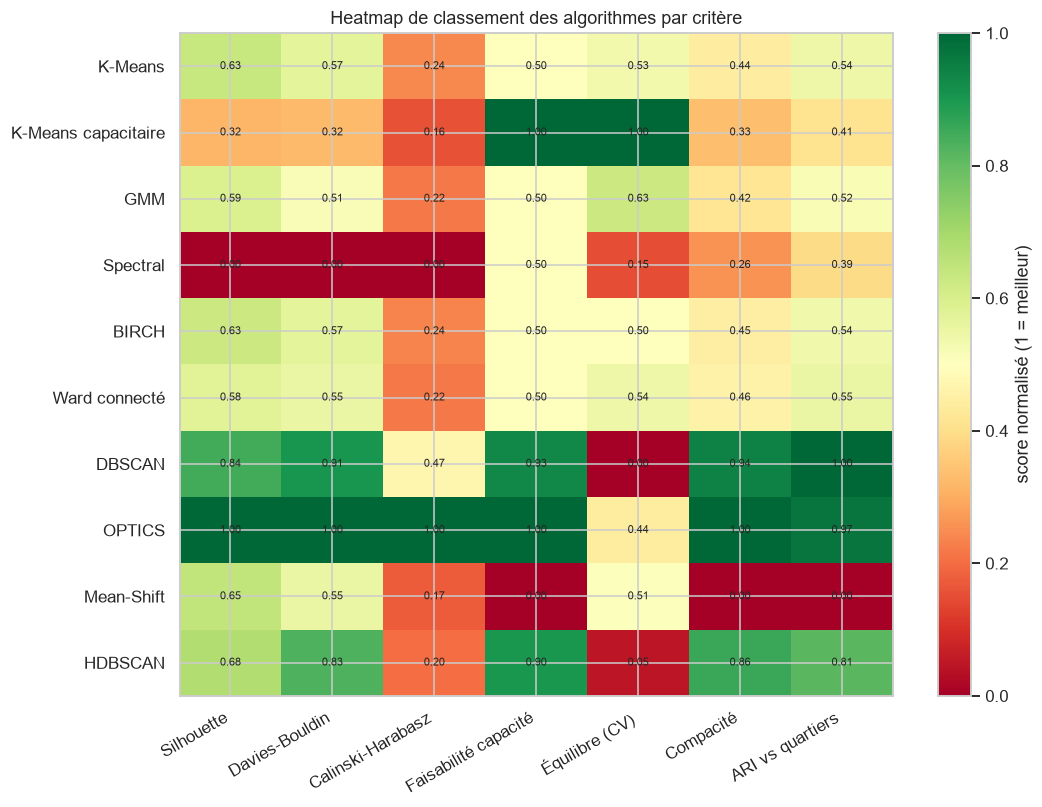

In [14]:
# Heatmap de classement : métriques normalisées (1 = meilleur) x algorithmes
def norm(s, higher=True):
    s = s.astype(float); r = s.max() - s.min()
    n = (s - s.min()) / r if r > 1e-12 else pd.Series(1.0, index=s.index)
    return n if higher else 1 - n

crit = {
    "Silhouette": norm(metrics["silhouette"], True),
    "Davies-Bouldin": norm(metrics["davies_bouldin"], False),
    "Calinski-Harabasz": norm(metrics["calinski_harabasz"], True),
    "Faisabilité capacité": norm(metrics["faisab_cap_%"], True),
    "Équilibre (CV)": norm(metrics["cv_tailles"], False),
    "Compacité": norm(metrics["intra_moy_m"], False),
    "ARI vs quartiers": norm(metrics["ARI_quartier"], True),
}
H = pd.DataFrame(crit).fillna(0)
plt.figure(figsize=(10, 0.55 * len(H) + 2))
im = plt.imshow(H.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
plt.colorbar(im, label="score normalisé (1 = meilleur)")
plt.xticks(range(H.shape[1]), H.columns, rotation=30, ha="right"); plt.yticks(range(len(H)), H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        plt.text(j, i, f"{H.values[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Heatmap de classement des algorithmes par critère")
savefig("c10_heatmap_classement.png"); plt.show()

**🔎 Approche.** **Radar** des 4 meilleurs : profil multi-critères pour visualiser d'un coup d'œil les compromis de chacun.

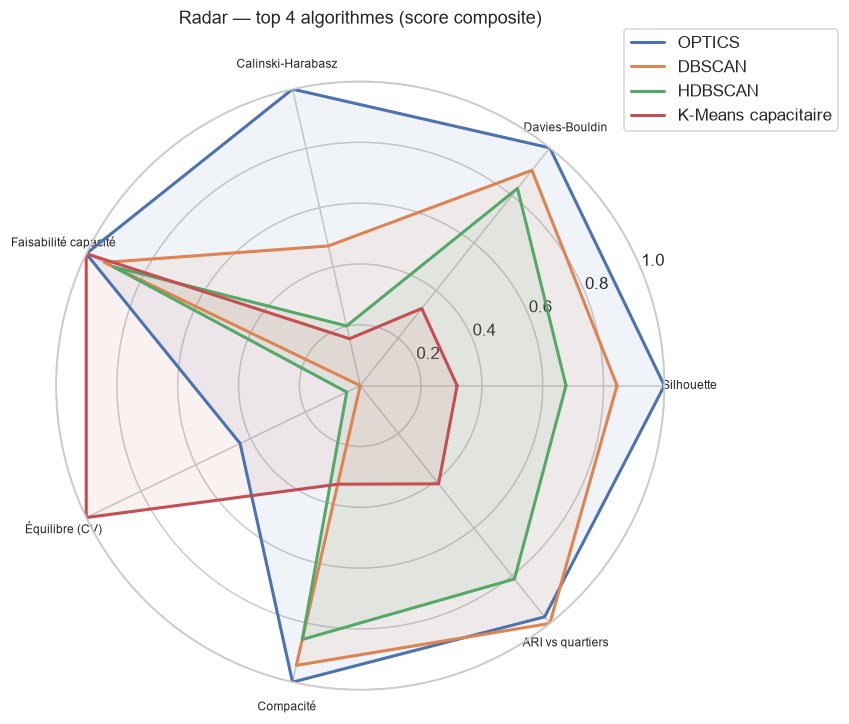

In [15]:
# Radar : comparaison des 4 meilleurs algorithmes (score composite) sur les critères normalisés
WEIGHTS = {"Silhouette":.22,"Davies-Bouldin":.13,"Calinski-Harabasz":.08,
           "Faisabilité capacité":.30,"Équilibre (CV)":.12,"Compacité":.10,"ARI vs quartiers":.05}
composite = sum(H[c] * w for c, w in WEIGHTS.items()).sort_values(ascending=False)
top = composite.head(4).index.tolist()

labels_r = list(WEIGHTS); ang = np.linspace(0, 2*np.pi, len(labels_r), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(8, 8)); ax = plt.subplot(111, polar=True)
for n in top:
    vals = H.loc[n, labels_r].tolist(); vals += vals[:1]
    ax.plot(ang, vals, lw=2, label=n); ax.fill(ang, vals, alpha=.08)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels_r, fontsize=8)
ax.set_ylim(0, 1); ax.set_title("Radar — top 4 algorithmes (score composite)", y=1.08)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
savefig("c11_radar.png"); plt.show()

## 7. Classement composite et recommandation

**🔎 Approche.** **Classement final** par score composite pondéré métier, avec rappel du choix de production.

In [16]:
rank = composite.rename("score_composite").to_frame()
rank["silhouette"]   = metrics["silhouette"].round(3)
rank["faisab_cap_%"] = metrics["faisab_cap_%"].round(1)
rank["n_clusters"]   = metrics["n_clusters"].astype(int)
rank["temps_ms"]     = metrics["temps_ms"]
print("Classement composite (pondéré métier) :")
display(rank)

best = composite.idxmax()
prod = "K-Means capacitaire"
print(f"\n→ Meilleur score composite : {best}")
print(f"→ Choix de PRODUCTION       : {prod}  "
      f"(faisabilité={metrics.loc[prod,'faisab_cap_%']:.0f}%, silhouette={metrics.loc[prod,'silhouette']:.2f})")

Classement composite (pondéré métier) :


,score_composite,silhouette,faisab_cap_%,n_clusters,temps_ms
OPTICS,0.931216,0.673,100.0,16,174.1
DBSCAN,0.765528,0.605,93.3,15,1.7
HDBSCAN,0.674937,0.532,90.0,10,7.0
K-Means capacitaire,0.598849,0.375,100.0,6,154.6
K-Means,0.517748,0.513,50.0,6,5983.8
BIRCH,0.512017,0.510,50.0,6,25.9
GMM,0.507477,0.494,50.0,6,16.4
Ward connecté,0.505509,0.489,50.0,6,13.2
Mean-Shift,0.288992,0.519,0.0,3,542.0
Spectral,0.213573,0.236,50.0,6,63.8



→ Meilleur score composite : OPTICS
→ Choix de PRODUCTION       : K-Means capacitaire  (faisabilité=100%, silhouette=0.38)


### Lecture & recommandation

- **Séparation pure vs exploitabilité.** Les méthodes qui maximisent la Silhouette (densité /
  spectral) trouvent peu de groupes très séparés mais **déséquilibrés et non bornés par la capacité**
  du bus — inexploitables tels quels pour le ramassage.
- **K-Means capacitaire** est le seul à **garantir `taille ≤ capacité`** (`GroupeEleves → 1 Bus`),
  au prix d'une Silhouette plus basse (la contrainte de taille découpe un continuum urbain).
- **GMM** apporte une information précieuse : les **points de faible confiance** (bordures) sont les
  candidats prioritaires pour les **déclencheurs de recalcul évolutif (S8)**.
- **La matrice d'accord (ARI)** identifie les regroupements « naturels » stables entre familles de
  méthodes — utile pour fixer les zones de ramassage robustes. Sur ces données réalistes
  (oued + secteurs), les méthodes de densité (DBSCAN/OPTICS/HDBSCAN) **isolent les secteurs denses
  et les élèves dispersés**, tandis que les méthodes à *k* découpent le territoire en groupes de
  ramassage.

**Recommandation retenue pour MS6 :** **K-Means capacitaire** en production (faisabilité garantie),
le benchmark servant de **justification méthodologique** dans le mémoire et de **diagnostic** de
séparabilité des données.

**🔎 Approche.** On sauvegarde la **synthèse** du benchmark dans un JSON (nombre d'algos, gagnant, classement) pour le mémoire et MS6.

In [17]:
summary = {
    "n_algorithmes": len(results),
    "projection": PROJ,
    "k_capacite": K, "capacite_bus": BUS_CAPACITY,
    "meilleur_composite": str(composite.idxmax()),
    "choix_production": "K-Means capacitaire",
    "classement": {n: round(float(composite[n]), 4) for n in composite.index},
}
Path("benchmark_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "n_algorithmes": 10,
  "projection": "UTM 30N (pyproj)",
  "k_capacite": 6,
  "capacite_bus": 50,
  "meilleur_composite": "OPTICS",
  "choix_production": "K-Means capacitaire",
  "classement": {
    "OPTICS": 0.9312,
    "DBSCAN": 0.7655,
    "HDBSCAN": 0.6749,
    "K-Means capacitaire": 0.5988,
    "K-Means": 0.5177,
    "BIRCH": 0.512,
    "GMM": 0.5075,
    "Ward connecté": 0.5055,
    "Mean-Shift": 0.289,
    "Spectral": 0.2136
  }
}


## 8. Conclusion

Ce benchmark compare **~11 algorithmes** de clustering sur des critères internes, métier, externes et
de robustesse, avec un large panel de visualisations (cartes + école, silhouettes, enveloppes
convexes, Voronoï, reachability OPTICS, confiance GMM, accord ARI, radar). Sur des données
**réalistes** (destination scolaire commune, séparation par l'oued, secteurs résidentiels denses,
élèves dispersés), il **objective** le choix de production (**K-Means capacitaire**) et fournit le
matériel méthodologique du mémoire.

➡️ *Suite (S8) :* exploiter la confiance GMM et la stabilité ARI comme **signaux de déclenchement**
du recalcul évolutif des groupes ; *portage MS6 :* `features.py` / `algorithms.py` / `evaluation.py`
/ `selection.py` reprennent cette logique validée.